<a href="https://colab.research.google.com/github/Nanzz1112/Project/blob/main/Tugas_Kelompok_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

WATER JUG  | ember 7L & 4L | goal: ember A = 5 L dan ember B = 0 L (kedua ember)

[A] TABEL LANGKAH PENCARIAN (urutan ekspansi BFS)
No  State diekspansi  Frontier setelah ekspansi
1   (0, 0)            [(7, 0), (0, 4)]
2   (7, 0)            [(0, 4), (7, 4), (3, 4)]
3   (0, 4)            [(7, 4), (3, 4), (4, 0)]
4   (7, 4)            [(3, 4), (4, 0)]
5   (3, 4)            [(4, 0), (3, 0)]
6   (4, 0)            [(3, 0), (4, 4)]
7   (3, 0)            [(4, 4), (0, 3)]
8   (4, 4)            [(0, 3), (7, 1)]
9   (0, 3)            [(7, 1), (7, 3)]
10  (7, 1)            [(7, 3), (0, 1)]
11  (7, 3)            [(0, 1), (6, 4)]
12  (0, 1)            [(6, 4), (1, 0)]
13  (6, 4)            [(1, 0), (6, 0)]
14  (1, 0)            [(6, 0), (1, 4)]
15  (6, 0)            [(1, 4), (2, 4)]
16  (1, 4)            [(2, 4), (5, 0)]
17  (2, 4)            [(5, 0), (2, 0)]
18  (5, 0)            [(2, 0)]

[B] JALUR SOLUSI
Langkah  Aksi                      State
0        Awal                      (0, 0)
1        

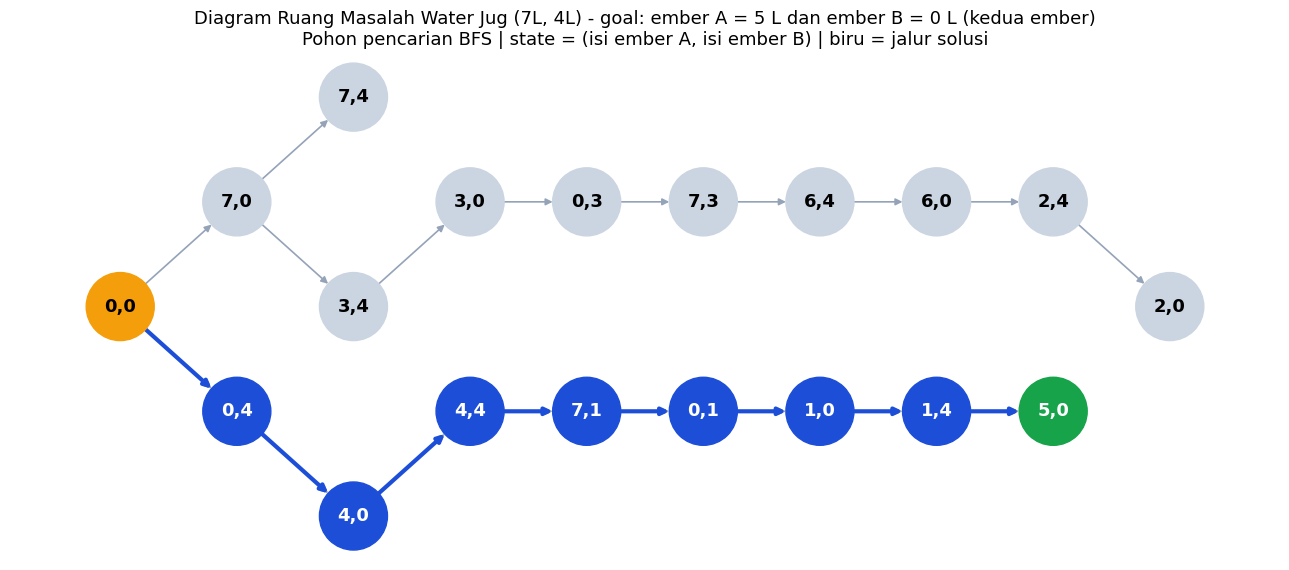


[D] Ilustrasi langkah-langkah (disimpan sebagai ilustrasi_langkah.png)


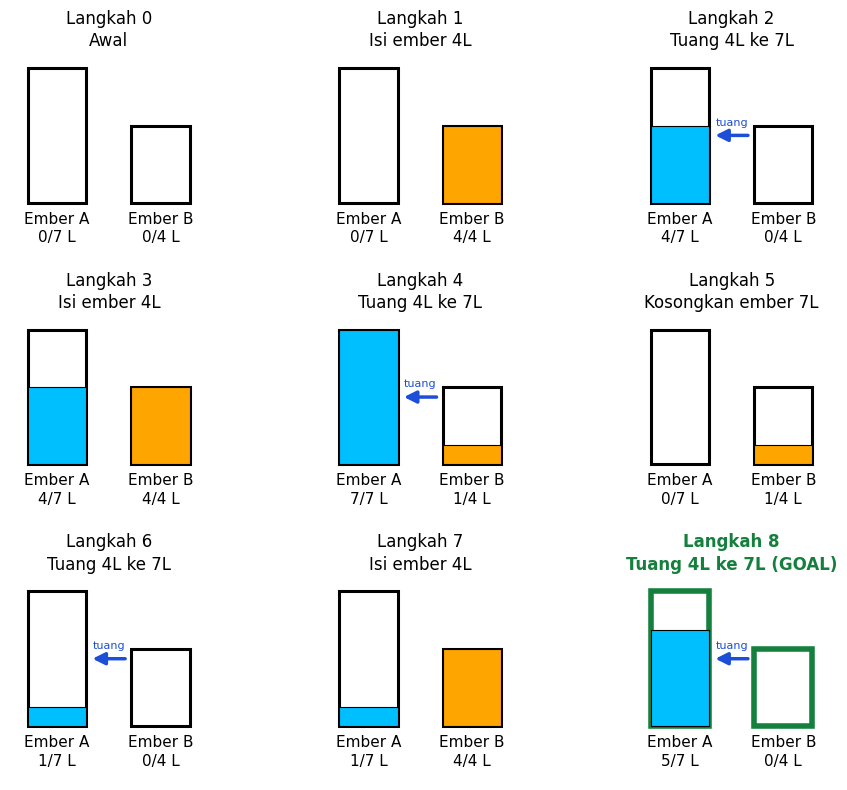

In [5]:
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

CAP_A = 7      # kapasitas ember A (liter)
CAP_B = 4      # kapasitas ember B (liter)

TARGET_A = 5     # isi akhir ember A (liter)
TARGET_B = 0    # isi akhir ember B (liter)


# 1. FORMULASI MASALAH
#    State   : (a, b)  -> isi ember A dan ember B
#    Initial : (0, 0)
#    Goal    : a == TARGET_A  DAN  b == TARGET_B  (kedua ember)
#    Action  : 6 aksi (isi A, isi B, kosongkan A, kosongkan B, tuang A->B, tuang B->A)
#    Cost    : tiap aksi = 1
INITIAL = (0, 0)

if not (0 <= TARGET_A <= CAP_A and 0 <= TARGET_B <= CAP_B):
    raise SystemExit(f"Target di luar kapasitas: TARGET_A harus 0..{CAP_A} dan TARGET_B harus 0..{CAP_B}.")

def ember_memenuhi(state):
    """Mengembalikan (A sudah sesuai target?, B sudah sesuai target?)."""
    a, b = state
    return (a == TARGET_A, b == TARGET_B)

def is_goal(state):
    ma, mb = ember_memenuhi(state)
    return ma and mb

GOAL_TEKS = f"ember A = {TARGET_A} L dan ember B = {TARGET_B} L (kedua ember)"

def successors(state):
    """Mengembalikan daftar (nama_aksi, state_baru) yang valid."""
    a, b = state
    hasil = []
    hasil.append((f"Isi ember {CAP_A}L", (CAP_A, b)))
    hasil.append((f"Isi ember {CAP_B}L", (a, CAP_B)))
    hasil.append((f"Kosongkan ember {CAP_A}L", (0, b)))
    hasil.append((f"Kosongkan ember {CAP_B}L", (a, 0)))
    t = min(a, CAP_B - b)                      # jumlah yang bisa dituang A -> B
    hasil.append((f"Tuang {CAP_A}L ke {CAP_B}L", (a - t, b + t)))
    t = min(b, CAP_A - a)                      # jumlah yang bisa dituang B -> A
    hasil.append((f"Tuang {CAP_B}L ke {CAP_A}L", (a + t, b - t)))
    # buang aksi yang tidak mengubah state
    return [(n, s) for n, s in hasil if s != state]


# 2. BFS  (mencatat urutan ekspansi, parent, dan seluruh sisi graf)
def bfs():
    frontier = deque([INITIAL])
    parent = {INITIAL: (None, "Awal")}
    explored_order = []          # urutan state yang di-ekspansi
    edges = []                   # (dari, ke, aksi) untuk gambar graf
    log = []                     # tabel langkah pencarian

    while frontier:
        current = frontier.popleft()
        explored_order.append(current)
        if is_goal(current):
            log.append((len(explored_order), current, "GOAL ditemukan", list(frontier)))
            return current, parent, explored_order, edges, log

        baru = []
        for nama, nxt in successors(current):
            edges.append((current, nxt, nama))
            if nxt not in parent:
                parent[nxt] = (current, nama)
                frontier.append(nxt)
                baru.append(nxt)
        log.append((len(explored_order), current, f"bangkitkan {baru}", list(frontier)))
    return None, parent, explored_order, edges, log

def rekonstruksi(goal, parent):
    jalur = []
    s = goal
    while s is not None:
        p, aksi = parent[s]
        jalur.append((aksi, s))
        s = p
    return list(reversed(jalur))

goal, parent, explored, edges, log = bfs()

if goal is None:
    raise SystemExit(f"Tidak ada solusi untuk ember {CAP_A}L & {CAP_B}L dengan goal: {GOAL_TEKS}. "
                     "(State yang bisa dicapai selalu punya minimal satu ember kosong atau penuh, "
                     "dan jumlah air yang bisa diukur selalu kelipatan dari FPB kedua kapasitas.)")


# 3. TAMPILKAN HASIL
print("=" * 60)
print(f"WATER JUG  | ember {CAP_A}L & {CAP_B}L | goal: {GOAL_TEKS}")
print("=" * 60)

print("\n[A] TABEL LANGKAH PENCARIAN (urutan ekspansi BFS)")
print(f"{'No':<4}{'State diekspansi':<18}{'Frontier setelah ekspansi'}")
for no, st, ket, fr in log:
    print(f"{no:<4}{str(st):<18}{fr}")

jalur = rekonstruksi(goal, parent)
print("\n[B] JALUR SOLUSI")
print(f"{'Langkah':<9}{'Aksi':<26}{'State'}")
for i, (aksi, st) in enumerate(jalur):
    tanda = "  <-- GOAL" if i == len(jalur) - 1 else ""
    print(f"{i:<9}{aksi:<26}{st}{tanda}")

print(f"\nJumlah langkah solusi : {len(jalur) - 1}")
print(f"State di-ekspansi     : {len(explored)}")
print(f"State ditemukan       : {len(parent)}")


# 4. DIAGRAM RUANG MASALAH  (pohon pencarian BFS per level)
#    Panah = aksi yang pertama kali menemukan state tsb (tree edge).
#    Biru = jalur solusi, oranye = initial, hijau = goal, abu = cabang lain.
depth = {INITIAL: 0}
for s in explored + [x for x in parent if x not in explored]:
    p, _ = parent[s]
    if p is not None:
        depth[s] = depth[p] + 1

levels = {}
for s in sorted(parent, key=lambda x: (depth[x], list(parent).index(x))):
    levels.setdefault(depth[s], []).append(s)

pos = {}
for d, nodes in levels.items():
    n = len(nodes)
    for i, s in enumerate(nodes):
        pos[s] = (d, (n - 1) / 2 - i)

G = nx.DiGraph()
for s, (p, aksi) in parent.items():
    G.add_node(s)
    if p is not None:
        G.add_edge(p, s)

jalur_states = [s for _, s in jalur]
jalur_edges = list(zip(jalur_states[:-1], jalur_states[1:]))

warna = []
for n in G.nodes:
    if n == INITIAL:
        warna.append("#f59e0b")
    elif is_goal(n) and n in jalur_states:
        warna.append("#16a34a")
    elif n in jalur_states:
        warna.append("#1d4ed8")
    else:
        warna.append("#cbd5e1")

plt.figure(figsize=(13, 5.8))
nx.draw_networkx_edges(G, pos, edge_color="#94a3b8", arrows=True, node_size=2400, width=1.2)
nx.draw_networkx_edges(G, pos, edgelist=jalur_edges, edge_color="#1d4ed8",
                       width=3, arrows=True, node_size=2400)
nx.draw_networkx_nodes(G, pos, node_color=warna, node_size=2400)
lab_color = {n: ("white" if c in ("#1d4ed8", "#16a34a") else "black") for n, c in zip(G.nodes, warna)}
for n, (x, y) in pos.items():
    plt.text(x, y, f"{n[0]},{n[1]}", ha="center", va="center", fontsize=13,
             color=lab_color[n], fontweight="bold")
plt.xticks(sorted(levels), [f"Level {d}" for d in sorted(levels)], fontsize=12)
plt.yticks([])
plt.title(f"Diagram Ruang Masalah Water Jug ({CAP_A}L, {CAP_B}L) - goal: {GOAL_TEKS}\n"
          "Pohon pencarian BFS | state = (isi ember A, isi ember B) | biru = jalur solusi", fontsize=13)
plt.box(False)
plt.tight_layout()
plt.savefig("diagram_ruang_masalah.png", dpi=200)
plt.show()


# 5. ILUSTRASI LANGKAH-LANGKAH (gambar ember per langkah)
#    Biru = isi ember A, oranye = isi ember B, panah = arah menuang.
import math
import numpy as np
from matplotlib.patches import Rectangle

WARNA_A, WARNA_B = "#00BFFF", "#FFA500"

def gambar_langkah(ax, idx, fs_title=12, fs_label=11):
    """Menggambar dua ember pada langkah ke-idx dari jalur solusi."""
    aksi, (a, b) = jalur[idx]
    skala = 6.0 / max(CAP_A, CAP_B)            # tinggi per liter
    xa, xb, lebar = 0.8, 5.4, 2.6              # posisi & lebar ember
    ax.clear()
    ax.set_xlim(0, 8.8)
    ax.set_ylim(-2.4, 6.6)
    ax.set_aspect("equal")
    ax.axis("off")

    langkah_goal = (idx == len(jalur) - 1) and is_goal((a, b))
    memenuhi = ember_memenuhi((a, b))
    for i, (x, isi, cap, warna, nama) in enumerate(((xa, a, CAP_A, WARNA_A, "Ember A"),
                                                    (xb, b, CAP_B, WARNA_B, "Ember B"))):
        hijau = langkah_goal and memenuhi[i]        # ember yang mencapai target diberi garis hijau tebal
        ax.add_patch(Rectangle((x, 0), lebar, cap * skala, fill=False,
                               ec="#15803d" if hijau else "black", lw=4.0 if hijau else 2.2))
        if isi > 0:
            ax.add_patch(Rectangle((x, 0), lebar, isi * skala, fc=warna, ec="black", lw=0.8))
        ax.text(x + lebar / 2, -0.4, f"{nama}\n{isi}/{cap} L",
                ha="center", va="top", fontsize=fs_label, linespacing=1.3)

    if aksi.startswith("Tuang"):               # panah arah menuang
        dari_a = aksi.startswith(f"Tuang {CAP_A}L")
        x1, x2 = (xa + lebar + 0.15, xb - 0.15) if dari_a else (xb - 0.15, xa + lebar + 0.15)
        ax.annotate("", xy=(x2, 3.0), xytext=(x1, 3.0),
                    arrowprops=dict(arrowstyle="-|>", lw=2.5, color="#1d4ed8", mutation_scale=18))
        ax.text(4.4, 3.35, "tuang", ha="center", va="bottom", fontsize=fs_label - 3, color="#1d4ed8")

    goal = (idx == len(jalur) - 1) and is_goal((a, b))
    judul = f"Langkah {idx}\n{aksi}" + (" (GOAL)" if goal else "")
    ax.set_title(judul, fontsize=fs_title, linespacing=1.3,
                 color="#15803d" if goal else "black", fontweight="bold" if goal else "normal")

def gambar_grid(nama_file, kolom=3, figsize=(10, 8), fs_title=12, fs_label=11):
    """Semua langkah dalam satu gambar (kotak-kotak)."""
    n = len(jalur)
    baris = math.ceil(n / kolom)
    fig, axes = plt.subplots(baris, kolom, figsize=figsize)
    axes = np.atleast_1d(axes).flatten()
    for i, ax in enumerate(axes):
        if i < n:
            gambar_langkah(ax, i, fs_title, fs_label)
        else:
            ax.axis("off")
            if i == n:
                ax.text(0.02, 0.85, "Keterangan", transform=ax.transAxes, fontsize=fs_title, fontweight="bold")
                for k, (warna, teks) in enumerate(((WARNA_A, f"isi ember A (maks {CAP_A} L)"),
                                                    (WARNA_B, f"isi ember B (maks {CAP_B} L)"))):
                    y = 0.65 - k * 0.17
                    ax.add_patch(Rectangle((0.02, y), 0.07, 0.09, transform=ax.transAxes, fc=warna, ec="black"))
                    ax.text(0.12, y + 0.045, teks, transform=ax.transAxes, va="center", fontsize=fs_label)
                ax.text(0.02, 0.28, "Panah biru = arah menuang", transform=ax.transAxes, fontsize=fs_label)
    plt.tight_layout()
    plt.savefig(nama_file, dpi=200)
    plt.show()

print("\n[D] Ilustrasi langkah-langkah (disimpan sebagai ilustrasi_langkah.png)")
gambar_grid("ilustrasi_langkah.png", kolom=3, figsize=(10, 8))